# 09 · Final evaluation on the test split

The **one** look at the test split (6,182 petitions decided January–August 2026). Every setting comes from
`reports/frozen_config.json` and the saved models; nothing below is chosen or changed after seeing a test result.

**Before this run**, the same code ran with `EVAL_SPLIT = "val"` (saving nothing) and reproduced the known validation
numbers of 05–08. That checked the code without touching the test labels.

What is measured:

1. **Classification:** the 2×2 comparison {TF-IDF + SVM, DistilRoBERTa} × {text only, + similarity features} and the
   raw models, with macro-F1, 95% bootstrap confidence intervals, accuracy, duplicate F1 and accept-vs-reject F1.
2. **Is the difference real?** McNemar tests between pairs of models.
3. **The final model** class by class, its calibration (ECE, reliability diagram) and the review flag (coverage vs accuracy).
4. **Duplicate retrieval:** BM25, MiniLM, mpnet and the hybrid on the open pool (main) and the stress pool.
5. **Out-of-scope test:** the 886 dropped petitions (fake-name, operational, foi), outcomes the model never learned.

**Input:** `data/processed/` (petitions, splits, gold pairs, similarity features, MiniLM / mpnet vectors), the test
and out-of-scope logits from `colab_test_logits.ipynb`, `models/` and `reports/frozen_config.json`.

**Output:** `reports/test_*.csv`, `reports/figures/*_test.png`, and the per-petition predictions for the error analysis
(`data/processed/predictions/final_test_predictions.parquet`, `retrieval_test_ranks.parquet`).

In [1]:
import json, sys, time
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from scipy.special import softmax
from scipy.stats import binomtest
from sklearn.metrics import classification_report, confusion_matrix, f1_score

ROOT = Path.cwd().parent                      # this notebook runs inside notebooks/
sys.path.insert(0, str(ROOT / "src"))
from preprocess import CLASSES, MODEL_INPUTS, leakage_check
from splits import CandidatePools
from retrieval import BM25Index, gold_rank, hybrid_scores, retrieval_metrics
from fusion import SIMILARITY_COLUMNS, apply_temperature, expected_calibration_error

EVAL_SPLIT = "test"           # "test" for the real run; "val" only for the code check (saves nothing)
SAVE = EVAL_SPLIT == "test"
DATA, REPORTS, MODELS = ROOT / "data" / "processed", ROOT / "reports", ROOT / "models"
FIGURES = REPORTS / "figures"

CONFIG = json.load(open(REPORTS / "frozen_config.json"))     # every setting below comes from here
SEED = CONFIG["seeds"]["random_state"]
ECE_BINS = CONFIG["evaluation"]["ece_bins"]
RESAMPLES = CONFIG["evaluation"]["bootstrap_resamples"]
THRESHOLD = CONFIG["review"]["threshold"]
POOL_LOW, POOL_HIGH = CONFIG["classification"]["pool_size_clip"]
K1, B, ALPHA = CONFIG["retrieval"]["bm25_k1"], CONFIG["retrieval"]["bm25_b"], CONFIG["retrieval"]["alpha"]
P_COLUMNS = [f"p_{c}" for c in CLASSES]
ALL_LABELS = list(range(len(CLASSES)))

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})
print("evaluating on:", EVAL_SPLIT, "| frozen settings:", json.dumps({k: CONFIG[k] for k in ["review", "retrieval"]}))

evaluating on: test | frozen settings: {"review": {"threshold": 0.75, "target_accuracy": 0.9}, "retrieval": {"final_method": "hybrid", "embedding_model": "all-MiniLM-L6-v2", "bm25_k1": 2.0, "bm25_b": 0.75, "alpha": 0.1}}


## 1. Load

In [2]:
petitions = pd.read_parquet(DATA / "petitions.parquet", columns=["id", "label", "text", "decision_time", "opened_at", "closed_at"])
petitions = petitions.merge(pd.read_parquet(DATA / "splits.parquet"), on="id", validate="one_to_one")
out_of_scope = pd.read_parquet(DATA / "out_of_scope.parquet", columns=["id", "label", "text"])
gold = pd.read_parquet(DATA / "gold_pairs.parquet")
similarity = pd.read_parquet(DATA / "predictions" / "similarity_features.parquet").set_index("id")
pools = CandidatePools(petitions)
by_id = petitions.set_index("id")

evaluate = petitions[petitions["split"] == EVAL_SPLIT].reset_index(drop=True)
assert len(evaluate) == {"val": 4_030, "test": 6_182}[EVAL_SPLIT] and len(out_of_scope) == 886
y = evaluate["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
print(f"{len(evaluate):,} {EVAL_SPLIT} petitions, {len(out_of_scope):,} out-of-scope petitions")
evaluate["label"].value_counts().reindex(CLASSES)

6,182 test petitions, 886 out-of-scope petitions


label
published            3017
duplicate            1737
irrelevant            505
no-action             563
honours                33
already-happening     103
local                 224
Name: count, dtype: int64

## 2. Scores of every model version

Each version uses exactly the frozen pieces: the TF-IDF vectorizers and SVM from 05, the DistilRoBERTa logits from
Colab, the temperature, the Platt scaler and the four fusion models from 08, and the pool size clipped to the
validation range (1,638–2,080), as decided in 08.

In [3]:
# TF-IDF + SVM: the saved vectorizers and SVM score the texts (the model is removed afterwards to free memory)
tfidf = joblib.load(MODELS / "tfidf_svc" / "model.joblib")
assert tfidf["classes"] == CLASSES

def svm_scores(frame):
    leakage_check(frame[MODEL_INPUTS])
    X = hstack([tfidf["word_vectorizer"].transform(frame["text"]), tfidf["char_vectorizer"].transform(frame["text"])], format="csr")
    return tfidf["svc"].decision_function(X)

SCORES = {"eval": svm_scores(evaluate), "oos": svm_scores(out_of_scope)}
del tfidf

# DistilRoBERTa: the logits computed on Colab (joined on id, never on row position)
def load_logits(file, ids):
    table = pd.read_parquet(DATA / "predictions" / file).set_index("id")
    assert set(table.index) == set(ids)
    return table.loc[ids, [f"logit_{c}" for c in CLASSES]].to_numpy()

eval_file = {"val": "distilroberta_val.parquet", "test": "distilroberta_test_logits.parquet"}[EVAL_SPLIT]
LOGITS = {"eval": load_logits(eval_file, evaluate["id"]),
          "oos": load_logits("distilroberta_out_of_scope_logits.parquet", out_of_scope["id"])}
print({k: v.shape for k, v in SCORES.items()}, {k: v.shape for k, v in LOGITS.items()})

{'eval': (6182, 7), 'oos': (886, 7)} {'eval': (6182, 7), 'oos': (886, 7)}


In [4]:
saved = joblib.load(MODELS / "fusion" / "fusion.joblib")
assert round(saved["temperature"], 4) == CONFIG["classification"]["temperature"]

def similarity_inputs(ids):
    features = similarity.loc[ids, SIMILARITY_COLUMNS].copy()
    features["pool_size"] = features["pool_size"].clip(POOL_LOW, POOL_HIGH)    # frozen decision of 08
    return features.to_numpy()

def fused(name, probabilities, ids):
    """Probabilities of one saved fusion model; its inputs pass the leakage check first."""
    X = pd.DataFrame(probabilities, columns=P_COLUMNS)
    if name.endswith("+similarity"):
        X[SIMILARITY_COLUMNS] = similarity_inputs(ids)
    leakage_check(X, allowed=P_COLUMNS + SIMILARITY_COLUMNS)
    return saved["fusion"][name].predict_proba(X.to_numpy())

def all_versions(part, ids):
    """(base, version) -> probabilities, or raw scores for the two raw versions."""
    svm_p = saved["platt"].transform(SCORES[part])
    roberta_p = apply_temperature(LOGITS[part], saved["temperature"])
    return {("tfidf_svc", "raw"): SCORES[part], ("tfidf_svc", "LR 7 probabilities"): fused("tfidf_svc", svm_p, ids),
            ("tfidf_svc", "LR 7 + 4 similarity"): fused("tfidf_svc+similarity", svm_p, ids),
            ("distilroberta", "raw"): LOGITS[part], ("distilroberta", "LR 7 probabilities"): fused("distilroberta", roberta_p, ids),
            ("distilroberta", "LR 7 + 4 similarity"): fused("distilroberta+similarity", roberta_p, ids)}

VERSIONS = all_versions("eval", evaluate["id"])
OOS_VERSIONS = all_versions("oos", out_of_scope["id"])
PRED = {k: v.argmax(axis=1) for k, v in VERSIONS.items()}
FINAL = ("distilroberta", "LR 7 + 4 similarity")
NAMES = {("tfidf_svc", "raw"): "TF-IDF + SVM", ("tfidf_svc", "LR 7 probabilities"): "TF-IDF + SVM, fusion (text only)",
         ("tfidf_svc", "LR 7 + 4 similarity"): "TF-IDF + SVM, fusion + similarity",
         ("distilroberta", "raw"): "DistilRoBERTa", ("distilroberta", "LR 7 probabilities"): "DistilRoBERTa, fusion (text only)",
         ("distilroberta", "LR 7 + 4 similarity"): "DistilRoBERTa, fusion + similarity (final)"}
print("versions:", list(NAMES.values()))

versions: ['TF-IDF + SVM', 'TF-IDF + SVM, fusion (text only)', 'TF-IDF + SVM, fusion + similarity', 'DistilRoBERTa', 'DistilRoBERTa, fusion (text only)', 'DistilRoBERTa, fusion + similarity (final)']


## 3. Main results with 95% confidence intervals

A **bootstrap** confidence interval: draw 1,000 new samples of the same size from the evaluated petitions (with
replacement), compute the score on each, and take the middle 95% of the 1,000 scores. The same 1,000 samples are used
for every model, so the models are compared on the same draws.

- **macro-F1:** the plain average of the 7 per-class F1 scores (the main metric).
- **accept-vs-reject F1:** the 6 rejection reasons merged into one "rejected" class (macro-F1 over 2 classes).
- The last column repeats the validation score (out-of-fold) from 08 for comparison.

In [5]:
def macro_f1(truth, predicted):
    return f1_score(truth, predicted, average="macro", labels=ALL_LABELS, zero_division=0)

rng = np.random.default_rng(SEED)
samples = rng.integers(0, len(y), size=(RESAMPLES, len(y)))

def confidence_interval(metric, truth, predicted):
    values = [metric(truth[s], predicted[s]) for s in samples]
    return np.percentile(values, [2.5, 97.5])

validation = pd.read_csv(REPORTS / "fusion_val_results.csv").set_index(["base", "version"])["macro_f1"]
start, rows = time.time(), []
for key, name in NAMES.items():
    predicted = PRED[key]
    low, high = confidence_interval(macro_f1, y, predicted)
    probabilities = None if key[1] == "raw" else VERSIONS[key]
    rows.append({"model": name, "macro_f1": macro_f1(y, predicted), "95% CI": f"{low:.3f}–{high:.3f}",
                 "accuracy": (predicted == y).mean(), "duplicate_f1": f1_score(y == 1, predicted == 1),
                 "accept_vs_reject_f1": f1_score(y == 0, predicted == 0, average="macro"),
                 "ece": np.nan if probabilities is None else expected_calibration_error(probabilities, y, ECE_BINS),
                 "validation_macro_f1": validation[key]})
results = pd.DataFrame(rows)
print(f"{RESAMPLES} bootstrap samples in {time.time() - start:.0f} s")
results.round(3)

1000 bootstrap samples in 10 s


,model,macro_f1,95% CI,accuracy,duplicate_f1,accept_vs_reject_f1,ece,validation_macro_f1
0,TF-IDF + SVM,0.415,0.391–0.435,0.637,0.471,0.763,NaN,0.445
1,"TF-IDF + SVM, fusion (text only)",0.523,0.497–0.544,0.683,0.602,0.816,0.036,0.505
2,"TF-IDF + SVM, fusion + similarity",0.552,0.527–0.574,0.722,0.707,0.833,0.010,0.559
3,DistilRoBERTa,0.521,0.497–0.544,0.680,0.491,0.799,NaN,0.556
4,"DistilRoBERTa, fusion (text only)",0.569,0.544–0.591,0.734,0.655,0.860,0.024,0.575
5,"DistilRoBERTa, fusion + similarity (final)",0.583,0.558–0.606,0.760,0.744,0.874,0.014,0.606


In [6]:
two_by_two = pd.DataFrame({"text only": [results.loc[1, "macro_f1"], results.loc[4, "macro_f1"]],
                           "+ similarity": [results.loc[2, "macro_f1"], results.loc[5, "macro_f1"]]},
                          index=["TF-IDF + SVM", "DistilRoBERTa"])
two_by_two["gain"] = two_by_two["+ similarity"] - two_by_two["text only"]
two_by_two.round(3)

,text only,+ similarity,gain
TF-IDF + SVM,0.523,0.552,0.029
DistilRoBERTa,0.569,0.583,0.015


## 4. Is the difference real? McNemar tests

Two models are compared on the petitions where **exactly one of them is right**. If the models were equally good,
those petitions would split about 50/50 between them; the p-value (exact binomial test) says how surprising the
actual split is. p < 0.05 means the difference is unlikely to be chance.

In [7]:
def mcnemar(a, b):
    a_right, b_right = PRED[a] == y, PRED[b] == y
    only_a, only_b = int((a_right & ~b_right).sum()), int((~a_right & b_right).sum())
    return only_a, only_b, binomtest(only_a, only_a + only_b, 0.5).pvalue

pairs = [(FINAL, ("distilroberta", "raw"), "final vs raw DistilRoBERTa"),
         (FINAL, ("distilroberta", "LR 7 probabilities"), "similarity features (DistilRoBERTa)"),
         (("tfidf_svc", "LR 7 + 4 similarity"), ("tfidf_svc", "LR 7 probabilities"), "similarity features (TF-IDF + SVM)"),
         (("distilroberta", "raw"), ("tfidf_svc", "raw"), "DistilRoBERTa vs TF-IDF + SVM (raw)"),
         (FINAL, ("tfidf_svc", "raw"), "final vs baseline")]
mcnemar_table = pd.DataFrame([{"comparison": label, "only first right": r[0], "only second right": r[1], "p_value": r[2],
                               "significant (p < 0.05)": r[2] < 0.05} for a, b, label in pairs for r in [mcnemar(a, b)]])
mcnemar_table.round(6)

,comparison,only first right,only second right,p_value,significant (p < 0.05)
0,final vs raw DistilRoBERTa,808,317,0.0,True
1,similarity features (DistilRoBERTa),380,220,0.0,True
2,similarity features (TF-IDF + SVM),422,179,0.0,True
3,DistilRoBERTa vs TF-IDF + SVM (raw),612,345,0.0,True
4,final vs baseline,1146,388,0.0,True


## 5. The final model, class by class

In [8]:
final_probabilities = VERSIONS[FINAL]
final_predicted = PRED[FINAL]
per_class = pd.DataFrame({"TF-IDF + SVM": f1_score(y, PRED[("tfidf_svc", "raw")], average=None, labels=ALL_LABELS, zero_division=0),
                          "DistilRoBERTa": f1_score(y, PRED[("distilroberta", "raw")], average=None, labels=ALL_LABELS, zero_division=0),
                          "final model": f1_score(y, final_predicted, average=None, labels=ALL_LABELS, zero_division=0),
                          "petitions": np.bincount(y, minlength=len(CLASSES))}, index=CLASSES)
print(per_class.round(3).to_string(), "\n")
print(classification_report(y, final_predicted, labels=ALL_LABELS, target_names=CLASSES, digits=3, zero_division=0))
matrix = confusion_matrix(y, final_predicted, labels=ALL_LABELS)
pd.DataFrame(matrix, index=[f"true {c}" for c in CLASSES], columns=CLASSES)

                   TF-IDF + SVM  DistilRoBERTa  final model  petitions
published                 0.798          0.829        0.877       3017
duplicate                 0.471          0.491        0.744       1737
irrelevant                0.481          0.543        0.507        505
no-action                 0.346          0.426        0.456        563
honours                   0.628          0.691        0.769         33
already-happening         0.057          0.107        0.130        103
local                     0.123          0.561        0.601        224 

                   precision    recall  f1-score   support

        published      0.839     0.918     0.877      3017
        duplicate      0.737     0.751     0.744      1737
       irrelevant      0.577     0.451     0.507       505
        no-action      0.535     0.398     0.456       563
          honours      0.781     0.758     0.769        33
already-happening      0.257     0.087     0.130       103
            loca

,published,duplicate,irrelevant,no-action,honours,already-happening,local
true published,2769,190,17,38,0,1,2
true duplicate,286,1305,37,95,1,13,0
true irrelevant,74,69,228,38,3,3,90
true no-action,103,170,53,224,2,8,3
true honours,2,4,1,1,25,0,0
true already-happening,44,27,3,19,1,9,0
true local,21,5,56,4,0,1,137


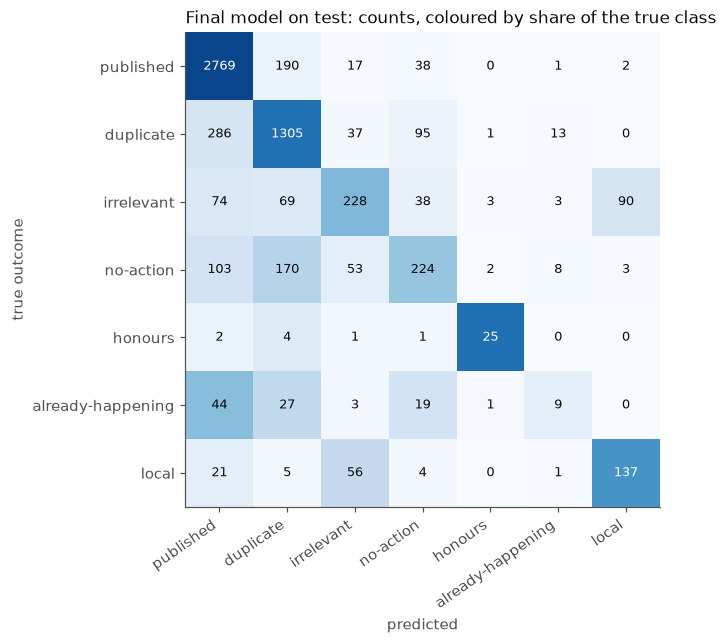

In [9]:
shares = matrix / matrix.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.2, 5.6))
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{matrix[i, j]}", ha="center", va="center", fontsize=8.5, color="white" if shares[i, j] > 0.55 else INK)
ax.set_xticks(ALL_LABELS, CLASSES, rotation=35, ha="right")
ax.set_yticks(ALL_LABELS, CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true outcome")
ax.grid(False)
ax.set_title(f"Final model on {EVAL_SPLIT}: counts, coloured by share of the true class", loc="left", fontsize=11)
if SAVE:
    fig.savefig(FIGURES / "confusion_test.png")
plt.show()

## 6. Calibration

Is the confidence honest on new petitions? ECE = average gap between confidence and accuracy (0 = perfect).

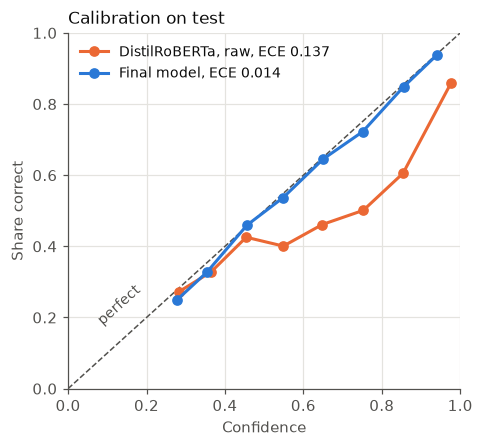

,model,ece
0,"DistilRoBERTa, raw (temperature 1)",0.137
1,"DistilRoBERTa, temperature 1.48",0.052
2,"TF-IDF + SVM, Platt",0.049
3,final model,0.014


In [10]:
calibration = pd.DataFrame([
    {"model": "DistilRoBERTa, raw (temperature 1)", "ece": expected_calibration_error(softmax(LOGITS["eval"], axis=1), y, ECE_BINS)},
    {"model": f"DistilRoBERTa, temperature {saved['temperature']:.2f}", "ece": expected_calibration_error(apply_temperature(LOGITS["eval"], saved["temperature"]), y, ECE_BINS)},
    {"model": "TF-IDF + SVM, Platt", "ece": expected_calibration_error(saved["platt"].transform(SCORES["eval"]), y, ECE_BINS)},
    {"model": "final model", "ece": expected_calibration_error(final_probabilities, y, ECE_BINS)}])

def reliability(probabilities, bins=10):
    confidence, correct = probabilities.max(axis=1), probabilities.argmax(axis=1) == y
    points = []
    for low, high in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.sum() >= 20:
            points.append((confidence[in_bin].mean(), correct[in_bin].mean()))
    return np.array(points)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.text(0.13, 0.18, "perfect", color=MUTED, ha="center", rotation=42, fontsize=9)
for probabilities, colour, name in [(softmax(LOGITS["eval"], axis=1), ORANGE, "DistilRoBERTa, raw"), (final_probabilities, BLUE, "Final model")]:
    points = reliability(probabilities)
    ax.plot(points[:, 0], points[:, 1], color=colour, linewidth=2, marker="o", markersize=6,
            label=f"{name}, ECE {expected_calibration_error(probabilities, y, ECE_BINS):.3f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Confidence"); ax.set_ylabel("Share correct")
ax.set_title(f"Calibration on {EVAL_SPLIT}", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left", fontsize=9)
if SAVE:
    fig.savefig(FIGURES / "reliability_test.png")
plt.show()
calibration.round(3)

## 7. The review flag

The frozen threshold (0.75) was chosen on validation so that about 63% of petitions are not flagged and about 90% of
those are correct. Does that hold on test?

threshold 0.75: 61.2% not flagged, 89.0% of them correct (validation: 62.8% and 90.5%); flagged petitions are correct 55.4% of the time


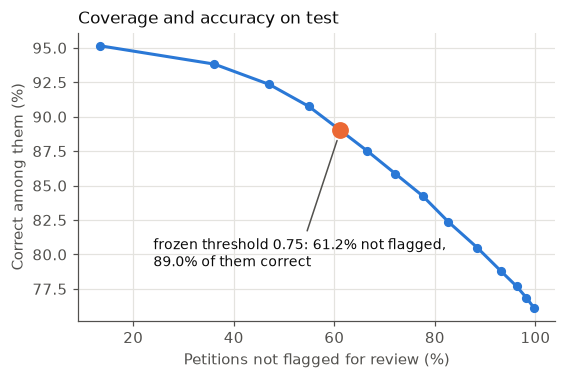

,threshold,not flagged,accuracy if not flagged
0,0.30,0.997,0.761
1,0.35,0.982,0.769
2,0.40,0.963,0.777
3,0.45,0.931,0.788
4,0.50,0.884,0.805
5,0.55,0.827,0.824
6,0.60,0.776,0.843
7,0.65,0.721,0.859
8,0.70,0.665,0.875
9,0.75,0.612,0.890


In [11]:
confidence = final_probabilities.max(axis=1)
correct = final_predicted == y
not_flagged = confidence >= THRESHOLD
print(f"threshold {THRESHOLD}: {not_flagged.mean():.1%} not flagged, {correct[not_flagged].mean():.1%} of them correct "
      f"(validation: 62.8% and 90.5%); flagged petitions are correct {correct[~not_flagged].mean():.1%} of the time")

thresholds = np.round(np.arange(0.30, 0.96, 0.05), 2)
curve = pd.DataFrame({"threshold": thresholds, "not flagged": [(confidence >= t).mean() for t in thresholds],
                      "accuracy if not flagged": [correct[confidence >= t].mean() for t in thresholds]})
point = curve[curve["threshold"] == THRESHOLD].iloc[0]
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(curve["not flagged"] * 100, curve["accuracy if not flagged"] * 100, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.plot(point["not flagged"] * 100, point["accuracy if not flagged"] * 100, color=ORANGE, marker="o", markersize=10, linestyle="none")
ax.annotate(f"frozen threshold {THRESHOLD:.2f}: {point['not flagged']:.1%} not flagged,\n{point['accuracy if not flagged']:.1%} of them correct",
            (point["not flagged"] * 100, point["accuracy if not flagged"] * 100), xytext=(24, curve["accuracy if not flagged"].min() * 100 + 3),
            textcoords="data", ha="left", color=INK, fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1, "shrinkB": 7})
ax.set_xlabel("Petitions not flagged for review (%)"); ax.set_ylabel("Correct among them (%)")
ax.set_title(f"Coverage and accuracy on {EVAL_SPLIT}", loc="left", fontsize=11)
if SAVE:
    fig.savefig(FIGURES / "coverage_accuracy_test.png")
plt.show()
curve.round(3)

## 8. Duplicate retrieval

The duplicates of the evaluated period that have at least one valid link, ranked against their pool at decision time,
with the frozen settings (BM25 k1 = 2.0, b = 0.75; hybrid α = 0.1). The open pool is the main result; the stress pool
adds every closed petition. Confidence intervals come from 1,000 bootstrap samples of the queries; McNemar compares
top-5 hits.

In [12]:
queries = evaluate[evaluate["id"].isin(gold["query_id"])].reset_index(drop=True)
gold_sets = gold.groupby("query_id")["target_id"].apply(set)
leakage_check(queries[MODEL_INPUTS])
leakage_check(by_id.loc[pools.ids, MODEL_INPUTS])
assert len(queries) == {"val": 1_155, "test": 1_728}[EVAL_SPLIT]

index = BM25Index(by_id.loc[pools.ids, "text"].tolist())

def load_vectors(name, wanted_ids):
    ids = np.load(DATA / "embeddings" / f"{name}_ids.npy")
    vectors = np.load(DATA / "embeddings" / f"{name}_vectors.npy", mmap_mode="r")
    row = pd.Series(np.arange(len(ids)), index=ids)
    return np.asarray(vectors[row.loc[wanted_ids].to_numpy()])

vectors = {name: (load_vectors(name, pools.ids), load_vectors(name, queries["id"])) for name in ["minilm", "mpnet"]}
METHODS = ["bm25", "minilm", "mpnet", "hybrid"]
ranks, start = {}, time.time()
for pool in ["open", "stress"]:
    found = {m: [] for m in METHODS}
    for i, (query_id, text, t) in enumerate(zip(queries["id"], queries["text"], queries["decision_time"])):
        mask = pools.mask(t, query_id, stress=(pool == "stress"))
        pool_ids = pools.ids[mask]
        bm25 = index.scores(text, mask, k1=K1, b=B)
        cosine = {name: (pool_vectors @ query_vectors[i])[mask] for name, (pool_vectors, query_vectors) in vectors.items()}
        for method, scores in [("bm25", bm25), ("minilm", cosine["minilm"]), ("mpnet", cosine["mpnet"]),
                               ("hybrid", hybrid_scores(bm25, cosine["minilm"], ALPHA))]:
            found[method].append(gold_rank(scores, pool_ids, gold_sets[query_id]))
    for method in METHODS:
        ranks[method, pool] = np.array(found[method], dtype=float)
print(f"{len(queries):,} queries, both pools, {time.time() - start:.0f} s")

query_samples = np.random.default_rng(SEED).integers(0, len(queries), size=(RESAMPLES, len(queries)))
rows = []
for pool in ["open", "stress"]:
    for method in METHODS:
        r = ranks[method, pool]
        recall5 = np.percentile([(r[s] <= 5).mean() for s in query_samples], [2.5, 97.5])
        mrr = np.percentile([(1 / r[s]).mean() for s in query_samples], [2.5, 97.5])
        rows.append({"pool": pool, "method": method, **retrieval_metrics(r),
                     "recall@5 95% CI": f"{recall5[0]:.3f}–{recall5[1]:.3f}", "mrr 95% CI": f"{mrr[0]:.3f}–{mrr[1]:.3f}"})
retrieval = pd.DataFrame(rows)
retrieval.round(4)

1,728 queries, both pools, 80 s


,pool,method,recall@1,recall@5,recall@10,mrr,recall@5 95% CI,mrr 95% CI
0,open,bm25,0.5440,0.8640,0.9259,0.6817,0.848–0.880,0.665–0.699
1,open,minilm,0.6701,0.9271,0.9728,0.7854,0.916–0.939,0.772–0.801
2,open,mpnet,0.6794,0.9311,0.9670,0.7892,0.919–0.943,0.775–0.804
3,open,hybrid,0.6852,0.9410,0.9797,0.7982,0.929–0.952,0.785–0.812
4,stress,bm25,0.2552,0.5301,0.6476,0.3874,0.508–0.553,0.371–0.405
5,stress,minilm,0.2749,0.5816,0.7286,0.4205,0.559–0.604,0.403–0.440
6,stress,mpnet,0.2928,0.6042,0.7292,0.4333,0.580–0.628,0.415–0.453
7,stress,hybrid,0.2957,0.6273,0.7593,0.4498,0.604–0.650,0.433–0.468


In [13]:
def top5_mcnemar(a, b):
    a_hit, b_hit = ranks[a, "open"] <= 5, ranks[b, "open"] <= 5
    only_a, only_b = int((a_hit & ~b_hit).sum()), int((~a_hit & b_hit).sum())
    return {"comparison": f"{a} vs {b}", "only first in top 5": only_a, "only second in top 5": only_b,
            "p_value": binomtest(only_a, only_a + only_b, 0.5).pvalue}

retrieval_tests = pd.DataFrame([top5_mcnemar("hybrid", "bm25"), top5_mcnemar("hybrid", "minilm"), top5_mcnemar("minilm", "bm25")])
retrieval_tests.round(6)

,comparison,only first in top 5,only second in top 5,p_value
0,hybrid vs bm25,158,25,0.000000
1,hybrid vs minilm,37,13,0.000936
2,minilm vs bm25,164,55,0.000000


## 9. Out-of-scope test

The 886 dropped petitions have outcomes the model never learned: fake-name (the creator's name, which the model never
sees), operational and foi. The model must still give them one of its 7 classes. The question is whether the
assistant handles them safely: it should not confidently call them **published**.

- **Safe (the Milestone-1 definition):** predicted as a rejection class with low confidence (flagged for review).
- Also reported: **not confidently published** = any rejection class, or flagged.

In [14]:
oos_probabilities = OOS_VERSIONS[FINAL]
oos_predicted = np.array(CLASSES)[oos_probabilities.argmax(axis=1)]
oos_flagged = oos_probabilities.max(axis=1) < THRESHOLD
published = oos_predicted == "published"
breakdown = pd.crosstab(pd.Series(np.where(published, "published", "a rejection class"), name="predicted"),
                        pd.Series(np.where(oos_flagged, "flagged (low confidence)", "not flagged"), name="review flag"), margins=True)
by_code = pd.DataFrame({"code": out_of_scope["label"], "safe": ~published & oos_flagged,
                        "not confidently published": ~(published & ~oos_flagged)}).groupby("code").agg(["mean", "size"])
print(f"safe (rejection class + flagged): {(~published & oos_flagged).mean():.1%} | "
      f"not confidently published: {(~(published & ~oos_flagged)).mean():.1%} | flagged: {oos_flagged.mean():.1%}")
print(pd.Series(oos_predicted).value_counts().to_string(), "\n")
print(by_code.round(3).to_string())
breakdown

safe (rejection class + flagged): 60.2% | not confidently published: 94.1% | flagged: 74.4%
duplicate            439
published            178
no-action            177
irrelevant            75
already-happening     11
local                  5
honours                1 

              safe      not confidently published     
              mean size                      mean size
code                                                  
fake-name    0.595  829                     0.941  829
foi          0.741   27                     1.000   27
operational  0.667   30                     0.900   30


review flag,flagged (low confidence),not flagged,All
predicted,,,
a rejection class,533,175,708
published,126,52,178
All,659,227,886


## 10. Save

In [15]:
if SAVE:
    results.round(4).to_csv(REPORTS / "test_classification.csv", index=False)
    two_by_two.round(4).to_csv(REPORTS / "test_two_by_two.csv")
    mcnemar_table.to_csv(REPORTS / "test_mcnemar.csv", index=False)
    per_class.round(4).to_csv(REPORTS / "test_per_class.csv")
    calibration.round(4).to_csv(REPORTS / "test_calibration.csv", index=False)
    curve.round(4).to_csv(REPORTS / "test_coverage.csv", index=False)
    retrieval.round(4).to_csv(REPORTS / "test_retrieval.csv", index=False)
    retrieval_tests.to_csv(REPORTS / "test_retrieval_mcnemar.csv", index=False)
    breakdown.to_csv(REPORTS / "test_out_of_scope.csv")
    final = pd.DataFrame({"id": evaluate["id"], "label": evaluate["label"], "predicted": np.array(CLASSES)[final_predicted],
                          "confidence": confidence, "flagged": ~not_flagged,
                          "distilroberta_predicted": np.array(CLASSES)[PRED[("distilroberta", "raw")]],
                          "tfidf_svc_predicted": np.array(CLASSES)[PRED[("tfidf_svc", "raw")]]})
    for i, c in enumerate(CLASSES):
        final[f"p_{c}"] = final_probabilities[:, i]
    final.to_parquet(DATA / "predictions" / "final_test_predictions.parquet", index=False)
    pd.DataFrame({"query_id": queries["id"], **{f"{m}_{p}": ranks[m, p] for m in METHODS for p in ["open", "stress"]}}
                 ).to_parquet(DATA / "predictions" / "retrieval_test_ranks.parquet", index=False)
    print("saved")
else:
    print("code check on validation: nothing saved")

saved


## Summary (test split, the one run)

**Classification**: 6,182 petitions decided January–August 2026. Macro-F1:

| | text only | + similarity |
|---|---|---|
| TF-IDF + SVM | 0.523 | 0.552 |
| DistilRoBERTa | 0.569 | **0.583** |

- **Final model** (DistilRoBERTa + similarity features): macro-F1 **0.583** (95% CI 0.558–0.606), accuracy 76.0%,
  duplicate F1 0.744, accept-vs-reject F1 0.874. For comparison: raw DistilRoBERTa 0.521, the TF-IDF + SVM baseline 0.415.
- **Each step helps, and McNemar says each difference is real** (p < 0.001):
  - final vs raw DistilRoBERTa: 808 petitions only the final model gets right, against 317 only the raw model gets right;
  - adding the similarity features: 380 against 220.
- **Test is lower than validation** (final 0.583 against 0.606 out-of-fold): later petitions differ in topics and
  class mix. The gain from the similarity features is also smaller (+0.015 against +0.032 for DistilRoBERTa).
- **Class by class:**
  - duplicates improve most (F1 0.491 → 0.744);
  - already-happening (0.130) and no-action (0.456) stay weak;
  - irrelevant drops a little (0.543 → 0.507), because 90 irrelevant petitions are predicted as local.
- **Calibration holds on new petitions:** ECE 0.137 (raw), 0.052 (temperature), 0.014 (final model).
- **Review flag** (threshold 0.75): 61.2% of petitions are not flagged and 89.0% of them are correct (validation:
  62.8% and 90.5%). Flagged petitions are correct only 55.4% of the time, so the flag points the moderator to the
  uncertain cases.

**Duplicate retrieval**: 1,728 test duplicates, open pool. Recall@5: BM25 0.864, MiniLM 0.927, mpnet 0.931, hybrid
**0.941** (95% CI 0.929–0.952), MRR 0.798.
- The hybrid beats BM25 (158 queries against 25, p < 0.001) and MiniLM (37 against 13, p < 0.001).
- On test, mpnet is slightly ahead of MiniLM, the opposite of validation. MiniLM was chosen on validation and stays.
- Stress pool (closed petitions included): hybrid Recall@5 0.627.

**Out-of-scope** (886 petitions with codes the model never learned):
- 60.2% are safe by the Milestone-1 definition (a rejection class and flagged for review);
- 94.1% are not confidently called published;
- 52 petitions (5.9%) are confidently predicted as published.
